# Assignment 03: Toxic Comment Classification with BERT
**Name:** Tarek Alam Bhuiyan  
**Student ID:** 1000129291

**Task:** classify a user comment as *toxic* or *not toxic* on the Civil Comments dataset.

**Pipeline**
1. Data loading, labelling (threshold 0.5) and subsetting
2. Transfer learning: frozen BERT-based encoder as a feature extractor (baseline)
3. Fine-tuning: unfreeze the encoder and train end-to-end (default hyperparameters)
4. Hyperparameter tuning: Optuna (TPE sampler + median pruner)
5. Final evaluation and comparison of the three models
6. Test on real-world text
7. Interpretability with SHAP

Run on a GPU runtime (Colab T4 is enough). Total runtime is roughly 45 to 75 minutes with the default sizes; reduce `N_TRAIN`, `N_TUNE_TRAIN` and `N_TRIALS` in the config cell if needed.

## 0. Setup

In [2]:
!pip -q install transformers datasets accelerate optuna shap scikit-learn matplotlib seaborn pandas

In [3]:
import os, json, random, gc, warnings
import numpy as np, pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns
from datasets import load_dataset
from transformers import (AutoTokenizer, AutoModel, AutoModelForSequenceClassification,
                          DataCollatorWithPadding, Trainer, TrainingArguments,
                          TrainerCallback, pipeline)
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, roc_auc_score,
                             average_precision_score, confusion_matrix, roc_curve,
                             precision_recall_curve, classification_report)
import optuna

warnings.filterwarnings("ignore")
SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed()
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "no GPU (this will be slow)")

Device: cuda | Tesla T4


### Configuration
**Model choice.** `distilbert-base-uncased` is the default BERT-based model: it keeps about 97% of BERT-base language understanding while being 40% smaller and about 60% faster, which makes a 12-trial hyperparameter search affordable on one GPU. To use the full model, set `MODEL_NAME = "bert-base-uncased"` (expect roughly 2x the runtime).

**Label threshold.** A comment is *toxic* (1) if `toxicity >= 0.5`, else *not toxic* (0).

In [4]:
CFG = dict(
    MODEL_NAME   = "distilbert-base-uncased",
    THRESHOLD    = 0.5,      # toxicity score -> binary label
    MAX_LEN      = 128,
    N_TRAIN      = 30000,    # final training subset (official train split)
    N_TUNE_TRAIN = 10000,    # smaller subset used inside the hyperparameter search
    N_VAL        = 5000,     # from official validation split
    N_TEST       = 5000,     # from official test split
    N_TRIALS     = 12,       # Optuna trials
    OUT_DIR      = "artifacts",
)
os.makedirs(CFG["OUT_DIR"], exist_ok=True)
print(json.dumps(CFG, indent=2))

{
  "MODEL_NAME": "distilbert-base-uncased",
  "THRESHOLD": 0.5,
  "MAX_LEN": 128,
  "N_TRAIN": 30000,
  "N_TUNE_TRAIN": 10000,
  "N_VAL": 5000,
  "N_TEST": 5000,
  "N_TRIALS": 12,
  "OUT_DIR": "artifacts"
}


## 1. Data: Civil Comments

In [5]:
raw = load_dataset("google/civil_comments")
print(raw)
print(raw["train"][0])

README.md:   0%|          | 0.00/7.73k [00:00<?, ?B/s]

data/train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  194MB            

data/train-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  187MB            

data/train-00001-of-00002.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

... (3 outputs left out)

Generating train split:   0%|          | 0/1804874 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/97320 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/97320 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'toxicity', 'severe_toxicity', 'obscene', 'threat', 'insult', 'identity_attack', 'sexual_explicit'],
        num_rows: 1804874
    })
    validation: Dataset({
        features: ['text', 'toxicity', 'severe_toxicity', 'obscene', 'threat', 'insult', 'identity_attack', 'sexual_explicit'],
        num_rows: 97320
    })
    test: Dataset({
        features: ['text', 'toxicity', 'severe_toxicity', 'obscene', 'threat', 'insult', 'identity_attack', 'sexual_explicit'],
        num_rows: 97320
    })
})
{'text': "This is so cool. It's like, 'would you want your mother to read this??' Really great idea, well done!", 'toxicity': 0.0, 'severe_toxicity': 0.0, 'obscene': 0.0, 'threat': 0.0, 'insult': 0.0, 'identity_attack': 0.0, 'sexual_explicit': 0.0}


In [6]:
def make_split(split, n, seed=SEED):
    d = raw[split].shuffle(seed=seed).select(range(n))
    d = d.map(lambda ex: {"labels": int(ex["toxicity"] >= CFG["THRESHOLD"])})
    return d.select_columns(["text", "toxicity", "labels"])

train_raw = make_split("train",      CFG["N_TRAIN"])
val_raw   = make_split("validation", CFG["N_VAL"])
test_raw  = make_split("test",       CFG["N_TEST"], seed=SEED + 1)

# the tuning subset is the first N_TUNE_TRAIN rows of the (already shuffled) training subset
tune_raw = train_raw.select(range(CFG["N_TUNE_TRAIN"]))

stats = pd.DataFrame({
    name: {"n": len(d), "toxic": int(sum(d["labels"])), "toxic_%": round(100 * np.mean(d["labels"]), 2)}
    for name, d in [("train", train_raw), ("tune_train", tune_raw), ("validation", val_raw), ("test", test_raw)]
}).T
display(stats)

Map:   0%|          | 0/30000 [00:00<?, ? examples/s]

Map:   0%|          | 0/5000 [00:00<?, ? examples/s]

Map:   0%|          | 0/5000 [00:00<?, ? examples/s]

,n,toxic,toxic_%
train,30000.0,2380.0,7.93
tune_train,10000.0,800.0,8.00
validation,5000.0,396.0,7.92
test,5000.0,401.0,8.02


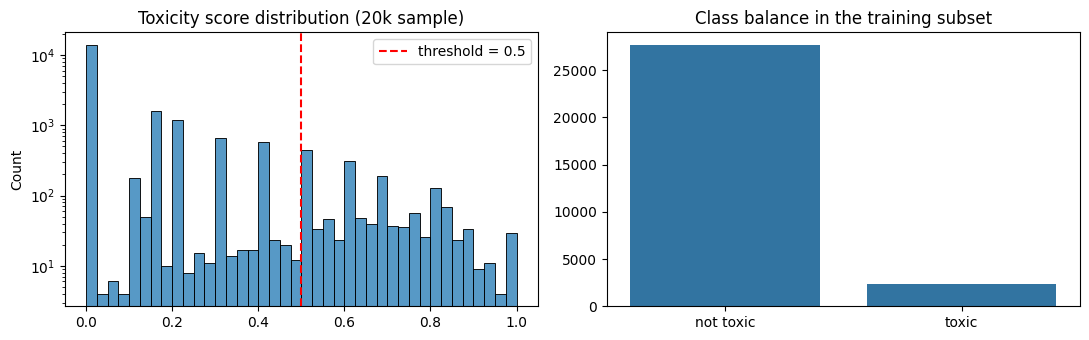

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
sns.histplot(raw["train"].shuffle(seed=0).select(range(20000))["toxicity"], bins=40, ax=ax[0])
ax[0].axvline(CFG["THRESHOLD"], color="red", ls="--", label=f"threshold = {CFG['THRESHOLD']}")
ax[0].set_title("Toxicity score distribution (20k sample)"); ax[0].set_yscale("log"); ax[0].legend()
sns.barplot(x=["not toxic", "toxic"], y=np.bincount(train_raw["labels"]), ax=ax[1])
ax[1].set_title("Class balance in the training subset")
plt.tight_layout(); plt.savefig(f"{CFG['OUT_DIR']}/data_overview.png", dpi=150); plt.show()

The data is heavily imbalanced (toxic is the minority class), so accuracy is misleading. We report **precision, recall, F1 (toxic class), ROC-AUC and PR-AUC**, and select models by **F1 on the validation set**. The fine-tuning loss also uses class weights.

## 2. Tokenisation

In [8]:
tokenizer = AutoTokenizer.from_pretrained(CFG["MODEL_NAME"])

def tokenize(batch):
    return tokenizer(batch["text"], truncation=True, max_length=CFG["MAX_LEN"])

def prep(d):
    return d.map(tokenize, batched=True).remove_columns(["text", "toxicity"])

train_ds, tune_ds, val_ds, test_ds = map(prep, [train_raw, tune_raw, val_raw, test_raw])
collator = DataCollatorWithPadding(tokenizer)
print(train_ds)



config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/30000 [00:00<?, ? examples/s]

Map:   0%|          | 0/10000 [00:00<?, ? examples/s]

Map:   0%|          | 0/5000 [00:00<?, ? examples/s]

Map:   0%|          | 0/5000 [00:00<?, ? examples/s]

Dataset({
    features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 30000
})


## 3. Shared evaluation helpers

In [10]:
def metrics_from_probs(y_true, p_toxic, thr=0.5):
    y_pred = (np.asarray(p_toxic) >= thr).astype(int)
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="binary", zero_division=0)
    return dict(accuracy=accuracy_score(y_true, y_pred), precision=p, recall=r, f1=f1,
                roc_auc=roc_auc_score(y_true, p_toxic), pr_auc=average_precision_score(y_true, p_toxic))

def compute_metrics(eval_pred):
    logits, y = eval_pred
    logits = logits - logits.max(-1, keepdims=True)
    probs = np.exp(logits) / np.exp(logits).sum(-1, keepdims=True)
    return metrics_from_probs(y, probs[:, 1])

RESULTS = {}   # name -> dict(val=..., test=..., p_test=...)

## 4. Transfer learning: frozen BERT as a feature extractor (baseline)
The pre-trained encoder is **frozen** (`requires_grad = False`, no gradient is computed). We extract one mean-pooled sentence vector per comment and train only a logistic regression head on top. This is the "before fine-tuning, before tuning" baseline.

In [11]:
@torch.no_grad()
def extract_features(dataset, model, batch_size=128):
    model.eval()
    feats = []
    loader = torch.utils.data.DataLoader(dataset.remove_columns(["labels"]), batch_size=batch_size, collate_fn=collator)
    for b in loader:
        b = {k: v.to(DEVICE) for k, v in b.items()}
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(DEVICE == "cuda")):
            h = model(**b).last_hidden_state
        m = b["attention_mask"].unsqueeze(-1).float()
        feats.append(((h.float() * m).sum(1) / m.sum(1)).cpu().numpy())   # masked mean pooling
    return np.vstack(feats)

encoder = AutoModel.from_pretrained(CFG["MODEL_NAME"]).to(DEVICE)
for p in encoder.parameters():
    p.requires_grad = False
print("Trainable encoder parameters:", sum(p.numel() for p in encoder.parameters() if p.requires_grad))

X_tr = extract_features(train_ds, encoder)
X_va = extract_features(val_ds, encoder)
X_te = extract_features(test_ds, encoder)
del encoder; gc.collect(); torch.cuda.empty_cache()
print(X_tr.shape, X_va.shape, X_te.shape)

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Trainable encoder parameters: 0
(30000, 768) (5000, 768) (5000, 768)


In [15]:
scaler = StandardScaler().fit(X_tr)
clf = LogisticRegression(C=1.0, class_weight="balanced", max_iter=3000, random_state=SEED)
clf.fit(scaler.transform(X_tr), train_ds["labels"])

pv = clf.predict_proba(scaler.transform(X_va))[:, 1]
pt = clf.predict_proba(scaler.transform(X_te))[:, 1]
RESULTS["1. Frozen BERT + LogReg (baseline)"] = dict(
    val=metrics_from_probs(val_ds["labels"], pv), test=metrics_from_probs(test_ds["labels"], pt), p_test=pt)
pd.DataFrame({k: v["test"] for k, v in RESULTS.items()}).T.round(4)

,accuracy,precision,recall,f1,roc_auc,pr_auc
1. Frozen BERT + LogReg (baseline),0.8136,0.2713,0.7855,0.4033,0.8797,0.4858


## 5. Fine-tuning: unfreeze and train end-to-end (default hyperparameters)
All encoder weights and the classification head are trained. The loss is cross-entropy with class weights `w_toxic = (n_neg / n_pos) ** power` (power = 0.5 by default), a softened inverse-frequency weighting that helps recall without destroying precision.

Default hyperparameters (common starting point for BERT): lr 2e-5, batch 32, 2 epochs, weight decay 0.01, warmup 10%, linear schedule.

In [22]:
DEFAULTS = dict(learning_rate=2e-5, per_device_train_batch_size=32, weight_decay=0.01,
                warmup_ratio=0.1, num_train_epochs=2, lr_scheduler_type="linear", pos_weight_power=0.5)

class WeightedTrainer(Trainer):
    def __init__(self, *args, **kwargs):
        self.class_weights = kwargs.pop("class_weights", None)
        super().__init__(*args, **kwargs)
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        w = self.class_weights.to(outputs.logits.device)
        loss = torch.nn.functional.cross_entropy(outputs.logits, labels, weight=w)
        return (loss, outputs) if return_outputs else loss

class OptunaPruningCallback(TrainerCallback):
    def __init__(self, trial): self.trial = trial
    def on_evaluate(self, args, state, control, metrics=None, **kw):
        self.trial.report(metrics["eval_f1"], step=int(round(state.epoch)))
        if self.trial.should_prune():
            raise optuna.TrialPruned()

def build_trainer(params, train_dataset, out_dir, trial=None):
    set_seed()
    model = AutoModelForSequenceClassification.from_pretrained(
        CFG["MODEL_NAME"], num_labels=2, id2label={0: "NOT_TOXIC", 1: "TOXIC"}, label2id={"NOT_TOXIC": 0, "TOXIC": 1})
    for p in model.parameters():
        p.requires_grad = True                                   # explicit: fully unfrozen
    labels = np.array(train_dataset["labels"])
    n_pos = labels.sum(); n_neg = len(labels) - n_pos
    cw = torch.tensor([1.0, (n_neg / n_pos) ** params["pos_weight_power"]], dtype=torch.float)
    args = TrainingArguments(
        output_dir=out_dir,
        learning_rate=params["learning_rate"], weight_decay=params["weight_decay"],
        num_train_epochs=params["num_train_epochs"],
        lr_scheduler_type=params["lr_scheduler_type"],
        per_device_train_batch_size=params["per_device_train_batch_size"], per_device_eval_batch_size=128,
        eval_strategy="epoch", save_strategy="epoch", save_total_limit=1,
        load_best_model_at_end=True, metric_for_best_model="f1", greater_is_better=True,
        fp16=(DEVICE == "cuda"), report_to="none", seed=SEED, logging_steps=100, disable_tqdm=False)
    cbs = [OptunaPruningCallback(trial)] if trial is not None else []

    # Attempt to pass both tokenizer and processing_class if supported, or fall back dynamically
    kwargs = {
        "model": model,
        "args": args,
        "train_dataset": train_dataset,
        "eval_dataset": val_ds,
        "data_collator": collator,
        "compute_metrics": compute_metrics,
        "class_weights": cw,
        "callbacks": cbs
    }
    import inspect
    trainer_sig = inspect.signature(Trainer.__init__)
    if "processing_class" in trainer_sig.parameters:
        kwargs["processing_class"] = tokenizer
    else:
        kwargs["tokenizer"] = tokenizer

    return WeightedTrainer(**kwargs)

def evaluate_trainer(trainer, name):
    pv = torch.softmax(torch.tensor(trainer.predict(val_ds).predictions), -1)[:, 1].numpy()
    pt = torch.softmax(torch.tensor(trainer.predict(test_ds).predictions), -1)[:, 1].numpy()
    RESULTS[name] = dict(val=metrics_from_probs(val_ds["labels"], pv),
                         test=metrics_from_probs(test_ds["labels"], pt), p_test=pt)

In [23]:
trainer_default = build_trainer(DEFAULTS, train_ds, f"{CFG['OUT_DIR']}/ft_default")
trainer_default.train()
evaluate_trainer(trainer_default, "2. Fine-tuned (default HPs)")
history_default = pd.DataFrame(trainer_default.state.log_history)
del trainer_default; gc.collect(); torch.cuda.empty_cache()
pd.DataFrame({k: v["test"] for k, v in RESULTS.items()}).T.round(4)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,Roc Auc,Pr Auc
1,0.276015,0.233513,0.939200,0.592000,0.747475,0.660714,0.949657,0.731675
2,0.181435,0.264365,0.946800,0.654028,0.696970,0.674817,0.951581,0.743171


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

,accuracy,precision,recall,f1,roc_auc,pr_auc
1. Frozen BERT + LogReg (baseline),0.8136,0.2713,0.7855,0.4033,0.8797,0.4858
2. Fine-tuned (default HPs),0.9396,0.6102,0.6833,0.6447,0.9317,0.7137


## 6. Hyperparameter tuning with Optuna
**Method:** Bayesian optimisation with the TPE sampler (more sample-efficient than grid or random search when each trial costs minutes), plus a **median pruner** that stops a trial after epoch 1 if its validation F1 is below the median of earlier trials.

**Search space (7 hyperparameters):**

| Hyperparameter | Range |
|---|---|
| learning rate | log-uniform [1e-5, 1e-4] |
| batch size | {16, 32} |
| weight decay | uniform [0.0, 0.1] |
| warmup ratio | uniform [0.0, 0.2] |
| epochs | {2, 3} |
| LR scheduler | {linear, cosine} |
| class-weight power | {0.0, 0.5, 1.0} |

**Objective:** maximise validation F1 (toxic class). Trials train on the smaller tuning subset (`N_TUNE_TRAIN`) to keep the search affordable; the best configuration is then retrained on the full training subset. The **test set is never used** during tuning.

In [24]:
def objective(trial):
    params = dict(
        learning_rate=trial.suggest_float("learning_rate", 1e-5, 1e-4, log=True),
        per_device_train_batch_size=trial.suggest_categorical("per_device_train_batch_size", [16, 32]),
        weight_decay=trial.suggest_float("weight_decay", 0.0, 0.1),
        warmup_ratio=trial.suggest_float("warmup_ratio", 0.0, 0.2),
        num_train_epochs=trial.suggest_int("num_train_epochs", 2, 3),
        lr_scheduler_type=trial.suggest_categorical("lr_scheduler_type", ["linear", "cosine"]),
        pos_weight_power=trial.suggest_categorical("pos_weight_power", [0.0, 0.5, 1.0]),
    )
    trainer = build_trainer(params, tune_ds, f"{CFG['OUT_DIR']}/tune_tmp", trial=trial)
    try:
        trainer.train()
        f1 = trainer.evaluate()["eval_f1"]
    finally:
        del trainer; gc.collect(); torch.cuda.empty_cache()
    return f1

study = optuna.create_study(direction="maximize", study_name="civil_comments_tuning",
                            sampler=optuna.samplers.TPESampler(seed=SEED),
                            pruner=optuna.pruners.MedianPruner(n_startup_trials=3, n_warmup_steps=0))
study.optimize(objective, n_trials=CFG["N_TRIALS"], gc_after_trial=True)
print("Best trial:", study.best_trial.number, "| best val F1 =", round(study.best_value, 4))
print(json.dumps(study.best_params, indent=2))

[I 2026-11-07 06:19:41,699] A new study created in memory with name: civil_comments_tuning


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,Roc Auc,Pr Auc
1,0.369633,0.253679,0.944800,0.651515,0.651515,0.651515,0.943630,0.695705
2,0.229487,0.354427,0.943800,0.645570,0.643939,0.644753,0.940194,0.708626


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (53 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1,Roc Auc,Pr Auc
0.121259,0.148254,2,0.946800,0.671958,0.641414,0.656331,0.943568,0.698386


[I 2026-11-07 06:33:43,433] Trial 11 finished with value: 0.6563307493540051 and parameters: {'learning_rate': 2.1809215164469237e-05, 'per_device_train_batch_size': 32, 'weight_decay': 0.08853861664332575, 'warmup_ratio': 0.00895725269980198, 'num_train_epochs': 2, 'lr_scheduler_type': 'linear', 'pos_weight_power': 0.0}. Best is trial 11 with value: 0.6563307493540051.


Best trial: 11 | best val F1 = 0.6563
{
  "learning_rate": 2.1809215164469237e-05,
  "per_device_train_batch_size": 32,
  "weight_decay": 0.08853861664332575,
  "warmup_ratio": 0.00895725269980198,
  "num_train_epochs": 2,
  "lr_scheduler_type": "linear",
  "pos_weight_power": 0.0
}


### Tuning results (use this table / figure as the screenshot for the README)

,number,value,learning_rate,lr_scheduler_type,num_train_epochs,per_device_train_batch_size,pos_weight_power,warmup_ratio,weight_decay,state,duration_min
0,11,0.6563,2.18e-05,linear,2,32,0.0,0.009,0.089,COMPLETE,1.8
1,2,0.6554,1.96e-05,linear,3,32,0.0,0.040,0.079,COMPLETE,2.5
2,0,0.6515,2.37e-05,cosine,2,16,0.5,0.031,0.060,COMPLETE,2.1
3,6,0.6425,1.38e-05,cosine,2,16,1.0,0.154,0.099,PRUNED,0.7
4,10,0.6418,3.22e-05,linear,3,32,0.0,0.049,0.018,PRUNED,0.6
5,4,0.6397,1.81e-05,linear,2,16,0.0,0.109,0.052,PRUNED,0.7
6,7,0.6361,1.19e-05,cosine,2,16,0.5,0.125,0.086,PRUNED,0.7
7,9,0.6352,1.28e-05,cosine,3,32,0.0,0.102,0.031,PRUNED,0.6
8,1,0.5946,9.33e-05,linear,2,16,0.5,0.037,0.018,COMPLETE,1.9
9,8,0.5942,7.71e-05,linear,3,16,0.0,0.152,0.071,PRUNED,0.8


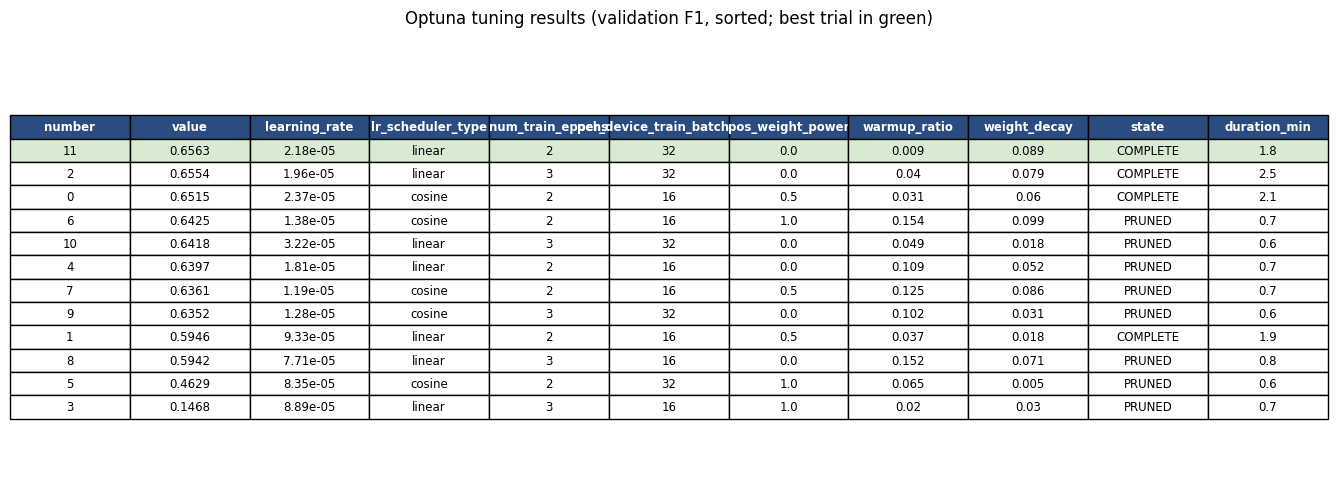

In [25]:
trials = study.trials_dataframe(attrs=("number", "value", "params", "state", "duration"))
trials.columns = [c.replace("params_", "") for c in trials.columns]
trials["duration_min"] = (trials["duration"].dt.total_seconds() / 60).round(1)
trials = trials.drop(columns="duration").sort_values("value", ascending=False).reset_index(drop=True)
trials["value"] = trials["value"].round(4)
for c in ["learning_rate"]: trials[c] = trials[c].map(lambda x: f"{x:.2e}")
for c in ["weight_decay", "warmup_ratio"]: trials[c] = trials[c].round(3)
trials.to_csv(f"{CFG['OUT_DIR']}/tuning_trials.csv", index=False)
display(trials)

# render the table as an image (screenshot for the report)
fig, ax = plt.subplots(figsize=(17, 0.5 + 0.45 * len(trials))); ax.axis("off")
tbl = ax.table(cellText=trials.values, colLabels=trials.columns, loc="center", cellLoc="center")
tbl.auto_set_font_size(False); tbl.set_fontsize(8.5); tbl.scale(1, 1.4)
for j in range(len(trials.columns)):
    tbl[(0, j)].set_facecolor("#2b4c7e"); tbl[(0, j)].set_text_props(color="white", weight="bold")
for j in range(len(trials.columns)):
    tbl[(1, j)].set_facecolor("#d9ead3")             # best trial highlighted
plt.title("Optuna tuning results (validation F1, sorted; best trial in green)", pad=12)
plt.savefig(f"{CFG['OUT_DIR']}/tuning_results_table.png", dpi=170, bbox_inches="tight"); plt.show()

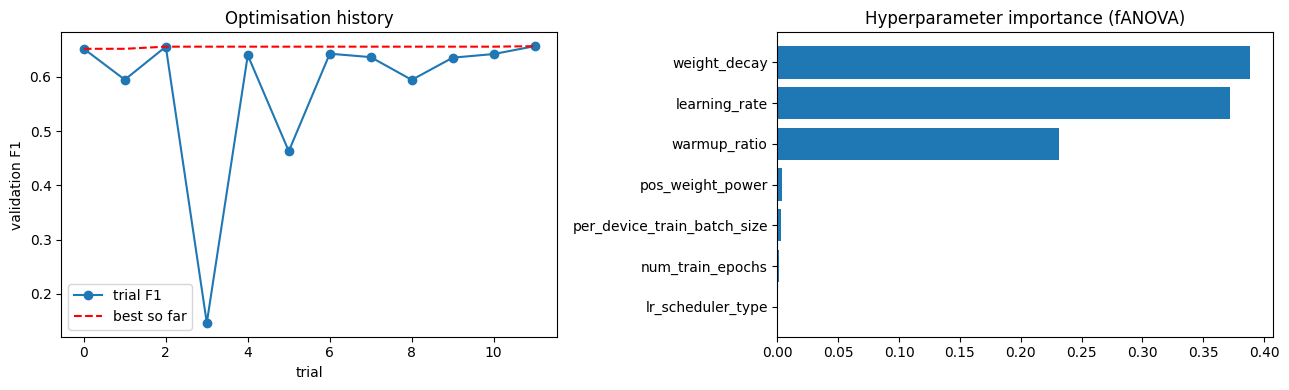

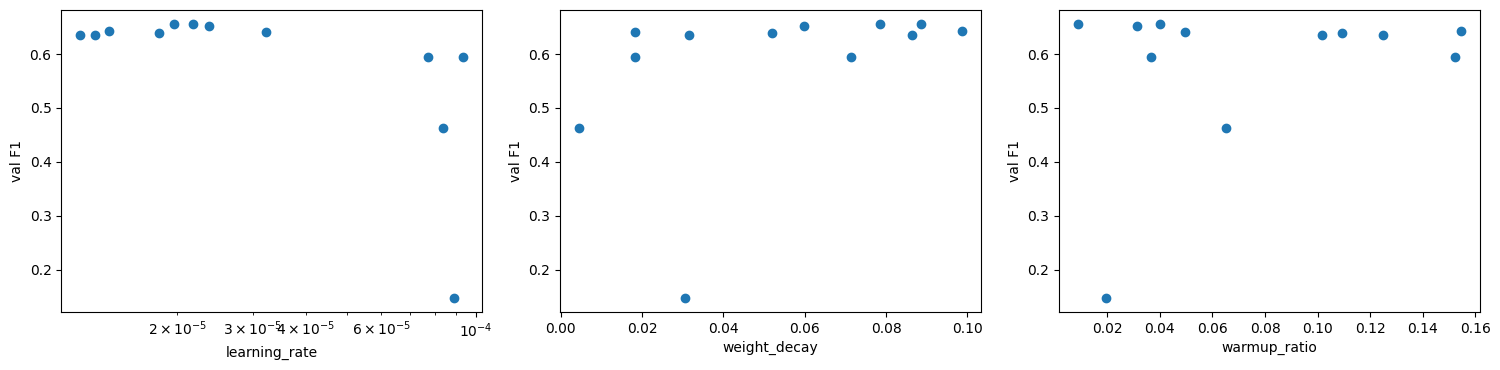

Pruned trials: 8 of 12


In [26]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
done = [t for t in study.trials if t.value is not None]
ax[0].plot([t.number for t in done], [t.value for t in done], "o-", label="trial F1")
ax[0].plot([t.number for t in done], np.maximum.accumulate([t.value for t in done]), "r--", label="best so far")
ax[0].set_xlabel("trial"); ax[0].set_ylabel("validation F1"); ax[0].set_title("Optimisation history"); ax[0].legend()
try:
    imp = optuna.importance.get_param_importances(study)
    ax[1].barh(list(imp.keys())[::-1], list(imp.values())[::-1]); ax[1].set_title("Hyperparameter importance (fANOVA)")
except Exception as e:
    ax[1].text(0.1, 0.5, f"importance unavailable: {e}"); ax[1].axis("off")
plt.tight_layout(); plt.savefig(f"{CFG['OUT_DIR']}/tuning_history_importance.png", dpi=150); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for a, p in zip(axes, ["learning_rate", "weight_decay", "warmup_ratio"]):
    a.scatter([t.params[p] for t in done], [t.value for t in done]); a.set_xlabel(p); a.set_ylabel("val F1")
    if p == "learning_rate": a.set_xscale("log")
plt.tight_layout(); plt.savefig(f"{CFG['OUT_DIR']}/tuning_scatter.png", dpi=150); plt.show()
print("Pruned trials:", sum(t.state == optuna.trial.TrialState.PRUNED for t in study.trials),
      "of", len(study.trials))

## 7. Final model: retrain the best configuration on the full training subset

In [27]:
best = {**DEFAULTS, **study.best_params}
print("Final hyperparameters:", best)
trainer_best = build_trainer(best, train_ds, f"{CFG['OUT_DIR']}/ft_tuned")
trainer_best.train()
evaluate_trainer(trainer_best, "3. Fine-tuned + tuned")
history_best = pd.DataFrame(trainer_best.state.log_history)
trainer_best.save_model(f"{CFG['OUT_DIR']}/best_model"); tokenizer.save_pretrained(f"{CFG['OUT_DIR']}/best_model")

Final hyperparameters: {'learning_rate': 2.1809215164469237e-05, 'per_device_train_batch_size': 32, 'weight_decay': 0.08853861664332575, 'warmup_ratio': 0.00895725269980198, 'num_train_epochs': 2, 'lr_scheduler_type': 'linear', 'pos_weight_power': 0.0}


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,Roc Auc,Pr Auc
1,0.156718,0.134494,0.949200,0.705202,0.616162,0.657682,0.950294,0.737143
2,0.095166,0.139339,0.952400,0.742331,0.611111,0.670360,0.951661,0.745137


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('artifacts/best_model/tokenizer_config.json',
 'artifacts/best_model/tokenizer.json')

## 8. Comparison: frozen baseline vs fine-tuned vs fine-tuned + tuned

In [28]:
rows = []
for name, r in RESULTS.items():
    rows.append({"model": name, **{f"val_{k}": v for k, v in r["val"].items()}, **{f"test_{k}": v for k, v in r["test"].items()}})
comp = pd.DataFrame(rows).set_index("model").round(4)
comp.to_csv(f"{CFG['OUT_DIR']}/comparison.csv")
display(comp[[c for c in comp.columns if c.startswith("test_")]])
display(comp[[c for c in comp.columns if c.startswith("val_")]])
json.dump({k: {"val": v["val"], "test": v["test"]} for k, v in RESULTS.items()},
          open(f"{CFG['OUT_DIR']}/results.json", "w"), indent=2)

,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc,test_pr_auc
model,,,,,,
1. Frozen BERT + LogReg (baseline),0.8136,0.2713,0.7855,0.4033,0.8797,0.4858
2. Fine-tuned (default HPs),0.9396,0.6102,0.6833,0.6447,0.9317,0.7137
3. Fine-tuned + tuned,0.9450,0.6800,0.5935,0.6338,0.9330,0.7103


,val_accuracy,val_precision,val_recall,val_f1,val_roc_auc,val_pr_auc
model,,,,,,
1. Frozen BERT + LogReg (baseline),0.8146,0.2602,0.7273,0.3832,0.8570,0.4292
2. Fine-tuned (default HPs),0.9468,0.6540,0.6970,0.6748,0.9516,0.7432
3. Fine-tuned + tuned,0.9524,0.7423,0.6111,0.6704,0.9517,0.7451


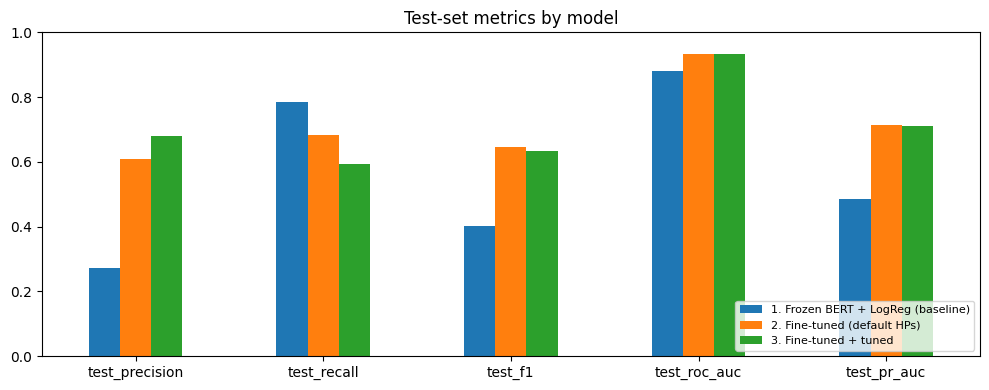

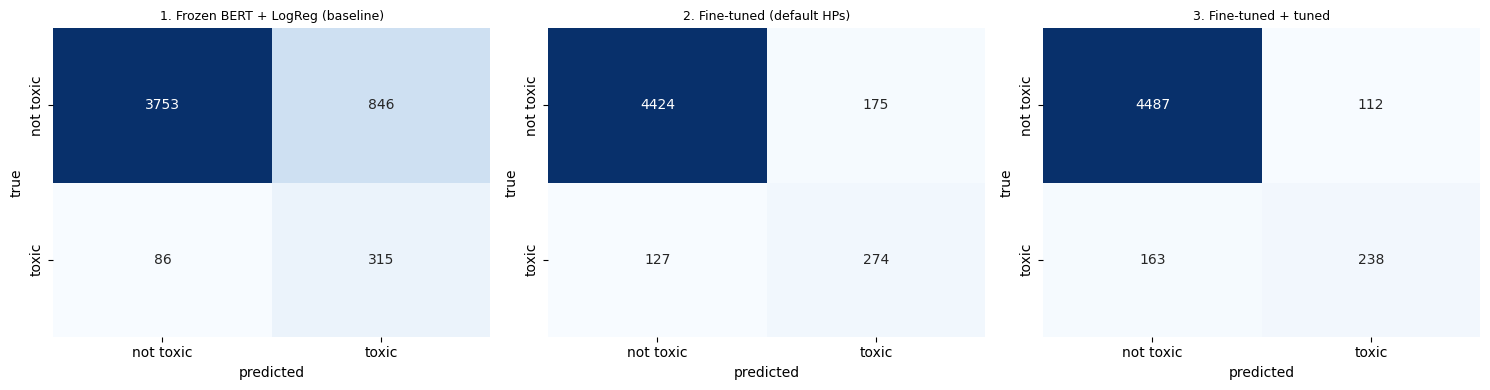

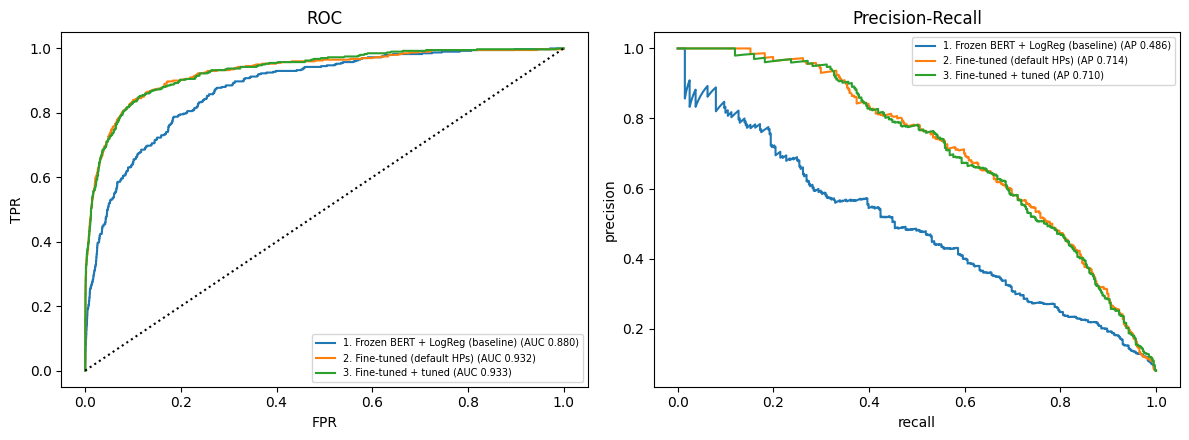

In [29]:
test_cols = ["test_precision", "test_recall", "test_f1", "test_roc_auc", "test_pr_auc"]
ax = comp[test_cols].T.plot(kind="bar", figsize=(10, 4), rot=0)
ax.set_ylim(0, 1); ax.set_title("Test-set metrics by model"); ax.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.savefig(f"{CFG['OUT_DIR']}/comparison_bar.png", dpi=150); plt.show()

y_test = np.array(test_ds["labels"])
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for a, (name, r) in zip(axes, RESULTS.items()):
    cm = confusion_matrix(y_test, (r["p_test"] >= 0.5).astype(int))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=a,
                xticklabels=["not toxic", "toxic"], yticklabels=["not toxic", "toxic"])
    a.set_title(name, fontsize=9); a.set_xlabel("predicted"); a.set_ylabel("true")
plt.tight_layout(); plt.savefig(f"{CFG['OUT_DIR']}/confusion_matrices.png", dpi=150); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for name, r in RESULTS.items():
    fpr, tpr, _ = roc_curve(y_test, r["p_test"]); ax[0].plot(fpr, tpr, label=f"{name} (AUC {r['test']['roc_auc']:.3f})")
    pr, rc, _ = precision_recall_curve(y_test, r["p_test"]); ax[1].plot(rc, pr, label=f"{name} (AP {r['test']['pr_auc']:.3f})")
ax[0].plot([0, 1], [0, 1], "k:"); ax[0].set_xlabel("FPR"); ax[0].set_ylabel("TPR"); ax[0].set_title("ROC"); ax[0].legend(fontsize=7)
ax[1].set_xlabel("recall"); ax[1].set_ylabel("precision"); ax[1].set_title("Precision-Recall"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.savefig(f"{CFG['OUT_DIR']}/roc_pr_curves.png", dpi=150); plt.show()

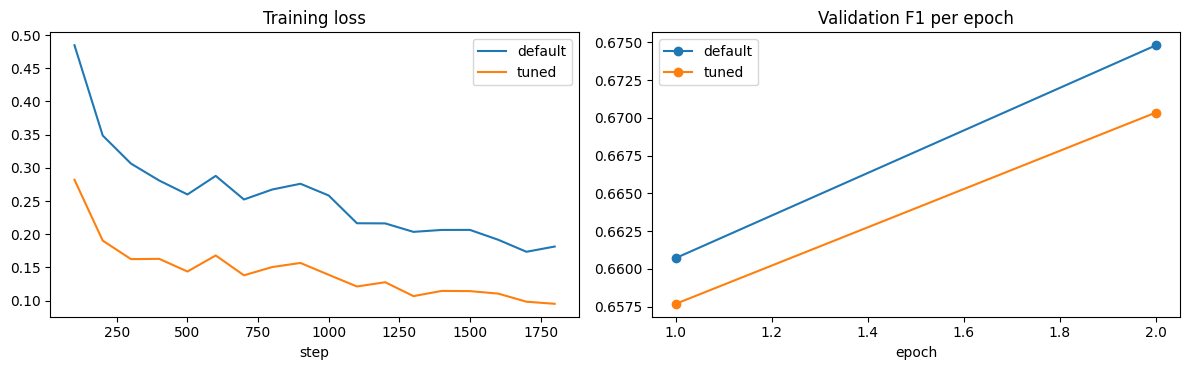

              precision    recall  f1-score   support

   not toxic     0.9649    0.9756    0.9703      4599
       toxic     0.6800    0.5935    0.6338       401

    accuracy                         0.9450      5000
   macro avg     0.8225    0.7846    0.8020      5000
weighted avg     0.9421    0.9450    0.9433      5000



In [30]:
# training curves of the fine-tuned runs (loss and validation F1 per epoch)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for name, h in [("default", history_default), ("tuned", history_best)]:
    tl = h.dropna(subset=["loss"]); ax[0].plot(tl["step"], tl["loss"], label=name)
    ev = h.dropna(subset=["eval_f1"]); ax[1].plot(ev["epoch"], ev["eval_f1"], "o-", label=name)
ax[0].set_title("Training loss"); ax[0].set_xlabel("step"); ax[0].legend()
ax[1].set_title("Validation F1 per epoch"); ax[1].set_xlabel("epoch"); ax[1].legend()
plt.tight_layout(); plt.savefig(f"{CFG['OUT_DIR']}/training_curves.png", dpi=150); plt.show()
print(classification_report(y_test, (RESULTS["3. Fine-tuned + tuned"]["p_test"] >= 0.5).astype(int),
                            target_names=["not toxic", "toxic"], digits=4))

## 9. Test on real-world text
Hand-written examples (not from Civil Comments) that cover: clear insults, polite disagreement, profanity used without targeting a person, identity terms used neutrally, sarcasm, a veiled threat and neutral text. `expected` is my own judgement of the correct label; the `check` column compares it with the model, and `comment` is left for a short manual analysis of each result.

In [31]:
best_model = trainer_best.model.eval()

real_world = [
    ("You are a complete idiot and nobody wants you here.", 1),
    ("I respectfully disagree with the author; the data in the second paragraph does not support the conclusion.", 0),
    ("This is the dumbest article I have ever read. The writer should be fired.", 1),
    ("What the hell, I can't believe the bus is late again today.", 0),
    ("As a Muslim woman, I think the new policy will help my community.", 0),
    ("People like you are a disease on this country. Go back where you came from.", 1),
    ("Great job destroying the competition last night, that was a brutal game!", 0),
    ("Oh sure, because you obviously know everything, genius.", 1),
    ("Keep talking and see what happens to you after work.", 1),
    ("The city council will meet on Tuesday to discuss the new bike lanes.", 0),
    ("Gay people deserve the same rights as everyone else.", 0),
    ("Shut up, you worthless piece of trash.", 1),
]

@torch.no_grad()
def predict_texts(texts, model=best_model):
    enc = tokenizer(texts, truncation=True, max_length=CFG["MAX_LEN"], padding=True, return_tensors="pt").to(model.device)
    return torch.softmax(model(**enc).logits.float(), -1)[:, 1].cpu().numpy()

rw_texts = [t for t, _ in real_world]; rw_exp = [e for _, e in real_world]
rw_p = predict_texts(rw_texts)
rw = pd.DataFrame({"input": rw_texts, "expected": ["toxic" if e else "not toxic" for e in rw_exp],
                   "predicted": ["toxic" if p >= 0.5 else "not toxic" for p in rw_p], "p_toxic": rw_p.round(3)})
rw["check"] = np.where(rw["expected"] == rw["predicted"], "correct", "MISMATCH")
rw["comment"] = ""     # <- write a one-line justification for each row before copying into the README
pd.set_option("display.max_colwidth", 100); pd.set_option("display.width", 250)
display(rw)
rw.to_csv(f"{CFG['OUT_DIR']}/real_world_predictions.csv", index=False)
print(f"Agreement with my manual labels: {(rw.check == 'correct').mean():.0%}")

,input,expected,predicted,p_toxic,check,comment
0,You are a complete idiot and nobody wants you here.,toxic,toxic,0.988,correct,
1,I respectfully disagree with the author; the data in the second paragraph does not support the c...,not toxic,not toxic,0.002,correct,
2,This is the dumbest article I have ever read. The writer should be fired.,toxic,toxic,0.980,correct,
3,"What the hell, I can't believe the bus is late again today.",not toxic,not toxic,0.017,correct,
4,"As a Muslim woman, I think the new policy will help my community.",not toxic,not toxic,0.048,correct,
5,People like you are a disease on this country. Go back where you came from.,toxic,toxic,0.769,correct,
6,"Great job destroying the competition last night, that was a brutal game!",not toxic,not toxic,0.010,correct,
7,"Oh sure, because you obviously know everything, genius.",toxic,not toxic,0.004,MISMATCH,
8,Keep talking and see what happens to you after work.,toxic,not toxic,0.002,MISMATCH,
9,The city council will meet on Tuesday to discuss the new bike lanes.,not toxic,not toxic,0.003,correct,


Agreement with my manual labels: 75%


## 10. Interpretability with SHAP
**Why SHAP:** it gives additive, model-agnostic token attributions grounded in Shapley values, so the contribution of each token to the TOXIC probability is on a consistent scale and can be compared across examples. Unlike raw attention weights, which are not reliable explanations of model decisions, SHAP measures the effect on the output of masking tokens. We use the Partition explainer through `shap.Explainer(pipeline)`, which handles text masking natively.

We explain a small, deliberately chosen set: one confident **true positive**, one confident **true negative**, one **false positive**, one **false negative** (all from the test set), plus real-world sentences.

In [32]:
p_test = RESULTS["3. Fine-tuned + tuned"]["p_test"]
texts_test = test_raw["text"]
tp = np.where((y_test == 1) & (p_test > 0.5))[0]; tn = np.where((y_test == 0) & (p_test < 0.5))[0]
fp = np.where((y_test == 0) & (p_test >= 0.5))[0]; fn = np.where((y_test == 1) & (p_test < 0.5))[0]
short = lambda idx: [i for i in idx if len(texts_test[i].split()) <= 45]       # keep plots readable
pick = {
    "True positive":  short(tp[np.argsort(-p_test[tp])])[0],
    "True negative":  short(tn[np.argsort(p_test[tn])])[0],
    "False positive": short(fp[np.argsort(-p_test[fp])])[0] if len(fp) else None,
    "False negative": short(fn[np.argsort(p_test[fn])])[0] if len(fn) else None,
}
cases = [(k, int(i), texts_test[int(i)], int(y_test[int(i)]), float(p_test[int(i)])) for k, i in pick.items() if i is not None]
# add 2 real-world sentences: a toxic one and a tricky non-toxic one (profanity without a target)
cases += [("Real-world (toxic)", -1, real_world[5][0], 1, float(rw_p[5])),
          ("Real-world (profanity, not toxic)", -1, real_world[3][0], 0, float(rw_p[3]))]
for k, i, t, y, p in cases:
    print(f"[{k}] true={'toxic' if y else 'not toxic'}  p_toxic={p:.3f}\n  {t}\n")

[True positive] true=toxic  p_toxic=0.988
  If stupid was a drug, you'd have overdosed

[True negative] true=not toxic  p_toxic=0.001
  No. If that was true then the green cards would be permanent and issued for life. No need to reinspect ever.

[False positive] true=not toxic  p_toxic=0.982
  Are you really saying 12.50 an hour is good? Holy crap, are you related to Bezo's? The largest company in the world owned by the wealthiest man in the world can't pay more then slave wages?

[False negative] true=toxic  p_toxic=0.001
  "That investment, at least according to Monday's sale price, is worth nothing."
No, it's worth 50% of its previous day value, plus 50% of the appreciation generated by the deal. Learn some capital accounting before writing ludicrous editorials.

[Real-world (toxic)] true=toxic  p_toxic=0.769
  People like you are a disease on this country. Go back where you came from.

[Real-world (profanity, not toxic)] true=not toxic  p_toxic=0.017
  What the hell, I can't believ

In [33]:
import shap
best_model.config.id2label = {0: "NOT_TOXIC", 1: "TOXIC"}
pipe = pipeline("text-classification", model=best_model, tokenizer=tokenizer, top_k=None,
                device=0 if DEVICE == "cuda" else -1, truncation=True, max_length=CFG["MAX_LEN"])
explainer = shap.Explainer(pipe)
case_texts = [c[2] for c in cases]
shap_values = explainer(case_texts)
print("SHAP computed for", len(case_texts), "texts")

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


  0%|          | 0/498 [00:00<?, ?it/s]

PartitionExplainer explainer: 7it [00:22,  5.68s/it]

SHAP computed for 6 texts


In [34]:
# interactive token highlighting (red pushes towards TOXIC, blue pushes away)
for (k, *_), i in zip(cases, range(len(cases))):
    print("###", k)
    shap.plots.text(shap_values[i, :, "TOXIC"])

### True positive


### True negative


### False positive


### False negative


### Real-world (toxic)


### Real-world (profanity, not toxic)


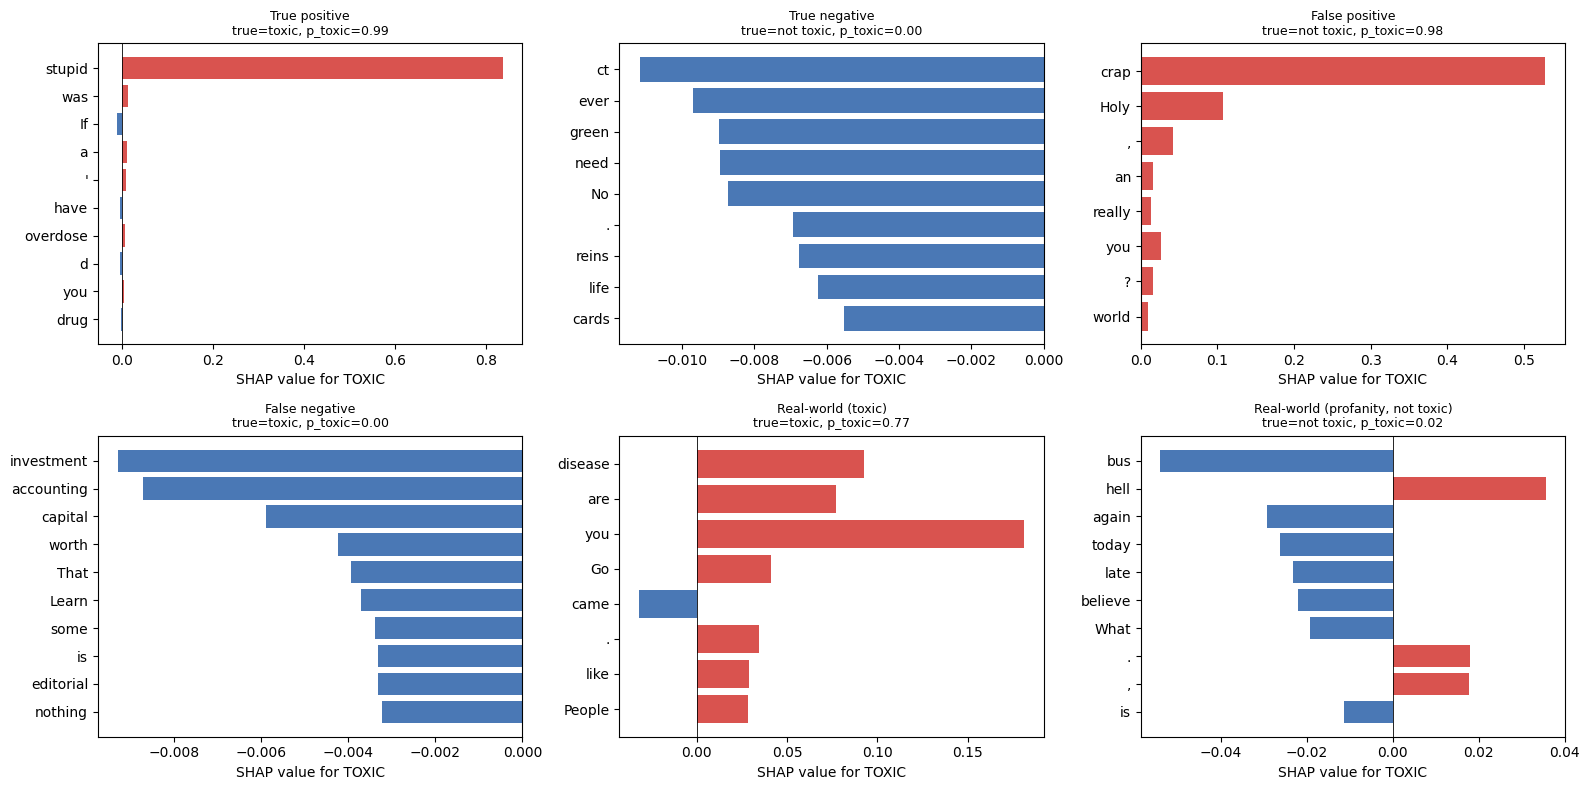

In [35]:
# static top-token bar charts (these are saved as PNG for the README)
def plot_case(ax, sv, title, topk=10):
    toks = np.array([t.strip() for t in sv.data]); vals = sv.values
    keep = [j for j, t in enumerate(toks) if t not in ("", "[CLS]", "[SEP]")]
    order = sorted(keep, key=lambda j: -abs(vals[j]))[:topk][::-1]
    ax.barh([toks[j] for j in order], [vals[j] for j in order],
            color=["#d9534f" if vals[j] > 0 else "#4a78b5" for j in order])
    ax.axvline(0, color="k", lw=0.6); ax.set_title(title, fontsize=9); ax.set_xlabel("SHAP value for TOXIC")

fig, axes = plt.subplots(2, 3, figsize=(16, 8)); axes = axes.ravel()
for a, (k, i, t, y, p), sv in zip(axes, cases, [shap_values[j, :, "TOXIC"] for j in range(len(cases))]):
    plot_case(a, sv, f"{k}\ntrue={'toxic' if y else 'not toxic'}, p_toxic={p:.2f}")
for a in axes[len(cases):]: a.axis("off")
plt.tight_layout(); plt.savefig(f"{CFG['OUT_DIR']}/shap_top_tokens.png", dpi=150); plt.show()

In [36]:
# summary table: most influential tokens per case, to support the written analysis
rows = []
for (k, i, t, y, p), j in zip(cases, range(len(cases))):
    sv = shap_values[j, :, "TOXIC"]; toks = [x.strip() for x in sv.data]
    ranked = sorted([(tk, float(v)) for tk, v in zip(toks, sv.values) if tk not in ("", "[CLS]", "[SEP]")], key=lambda z: -abs(z[1]))[:5]
    rows.append({"case": k, "true": "toxic" if y else "not toxic", "p_toxic": round(p, 3),
                 "top_tokens (SHAP)": ", ".join(f"{a} ({b:+.2f})" for a, b in ranked)})
shap_table = pd.DataFrame(rows); shap_table.to_csv(f"{CFG['OUT_DIR']}/shap_summary.csv", index=False)
display(shap_table)

,case,true,p_toxic,top_tokens (SHAP)
0,True positive,toxic,0.988,"stupid (+0.84), was (+0.01), If (-0.01), a (+0.01), ' (+0.01)"
1,True negative,not toxic,0.001,"ct (-0.01), ever (-0.01), green (-0.01), need (-0.01), No (-0.01)"
2,False positive,not toxic,0.982,"crap (+0.53), Holy (+0.11), , (+0.04), you (+0.03), ? (+0.02)"
3,False negative,toxic,0.001,"investment (-0.01), accounting (-0.01), capital (-0.01), worth (-0.00), That (-0.00)"
4,Real-world (toxic),toxic,0.769,"you (+0.18), disease (+0.09), are (+0.08), you (+0.05), Go (+0.04)"
5,"Real-world (profanity, not toxic)",not toxic,0.017,"bus (-0.05), hell (+0.04), again (-0.03), today (-0.03), late (-0.02)"


### How to read the SHAP output
- **Positive (red) SHAP values** push the prediction towards *toxic*; **negative (blue)** push towards *not toxic*. The sum of all token values plus the base value equals the model output.
- For each selected case, check: (1) do the top tokens match human intuition (insults, slurs, threats)? (2) for the false positive and false negative, which token misled the model (for example profanity without a target, sarcasm, or identity terms)? (3) do identity words such as *Muslim* or *gay* receive a positive toxic contribution? If so, that indicates the identity-term bias that is known to exist in Civil Comments.

## 11. Save artifacts

In [37]:
print(sorted(os.listdir(CFG["OUT_DIR"])))
# from google.colab import files; import shutil; shutil.make_archive("artifacts", "zip", CFG["OUT_DIR"]); files.download("artifacts.zip")

['best_model', 'comparison.csv', 'comparison_bar.png', 'confusion_matrices.png', 'data_overview.png', 'ft_default', 'ft_tuned', 'real_world_predictions.csv', 'results.json', 'roc_pr_curves.png', 'shap_summary.csv', 'shap_top_tokens.png', 'training_curves.png', 'tune_tmp', 'tuning_history_importance.png', 'tuning_results_table.png', 'tuning_scatter.png', 'tuning_trials.csv']
